## Downstream Analysis

Note: Please run the notebook Patch_PatchEmbeddings_Unimodel.ipynb before this notebook, as it is responsible for creating the patches, patch embeddings and metadata needed for this notebook.

**PCA (Principal Component Analysis)**:  
We run PCA with a reduction to 50 components (UNI model has 1536 features).  
Results are stored in adata.obsm["X_pca"] (PCA components (n x 50)).

**UMAP (Uniform Manifold Approximation and Projection for Dimension Reduction)**:  


**Leiden Clustering**:

*Please also note*: if you have already run the initial PCA and filtered but would like to rerun leiden or other methods, run the following 3 cells and then skip to step 3. 
BUT: be aware that if you have also already performed step 3 and now rerun step 3 on the file `filtered_WSI_patch_embeddings.h5ad`, this might skew the results.

In [2]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path
import random
import scanpy as sc
import seaborn as sns
import sys
from tqdm import tqdm

sys.path.insert(0, str(Path("../../../../").resolve()))
from functions import plotting as pl

In [3]:
basedir = Path("../../../../data")
sample = "CRC_P4_SMAP"  # set to any sample for single slide eval or to None for multi-slide eval
dir_uni = basedir / (sample or "combined") / "01_preprocessing/unimodel"
dir_metadata = dir_uni / "metadata"
leiden_res = [0.2, 0.5, 1.0, 2.0] # optional leiden resolutions for clustering
chosen_res = 0.5 # desired leiden res. can be changed again later based on cluster count

In [4]:
# Leiden Clustering
def run_leiden(adata, leiden_res):
    for res in leiden_res:
        key = f"leiden_{res}"
        sc.tl.leiden(adata, resolution=res, key_added=key)

# 1. Clustering
In this section we perform clustering using methods such as leiden and PCA. Depending on the previous choices, this can either be done sample specific or over all samples. 
The second step will then follow up with manually filtering out patches that do not include any tissue. 
Step 3 then reruns the clustering and plots the new clusters.

In [4]:
adata = sc.read(dir_metadata / "WSI_patch_metadata.h5ad")
print(adata.obs["Slide_ID"].unique()) 

['CRC_P11mm_2_cut']
Categories (1, object): ['CRC_P11mm_2_cut']


In [5]:
# PCA
sc.pp.pca(adata, n_comps=50)
sc.pp.neighbors(adata, use_rep="X_pca")

/home/charlottewolf/miniconda3/envs/uni/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
# UMAP + leiden
sc.tl.umap(adata)

In [7]:
# Leiden with resolution set in initial cell
run_leiden(adata, leiden_res)

/tmp/ipykernel_48309/1298289415.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=res, key_added=key)


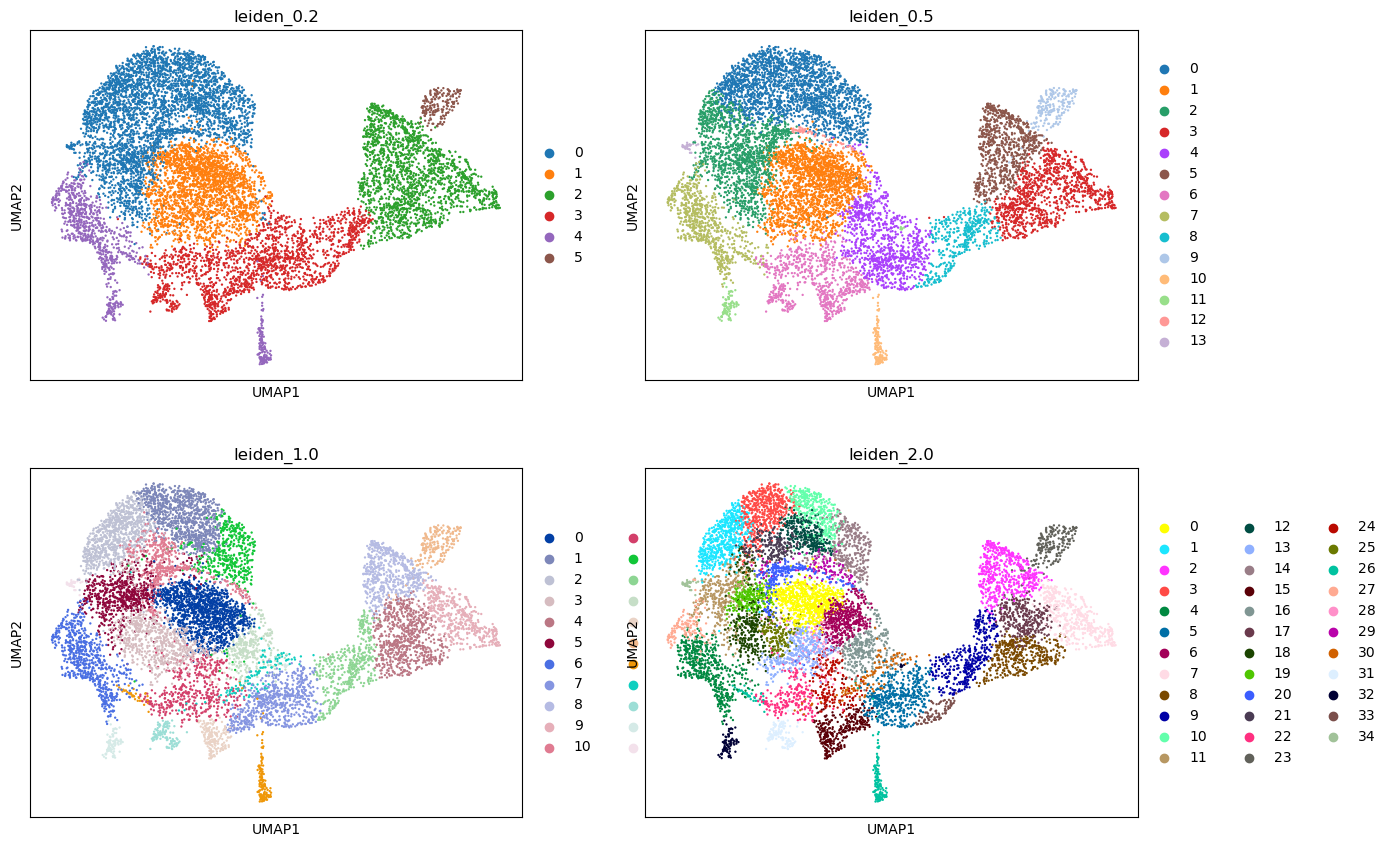

<Figure size 640x480 with 0 Axes>

In [8]:
umap_res = ["leiden_0.2", "leiden_0.5", "leiden_1.0", "leiden_2.0"]

sc.pl.umap(adata, 
           color=umap_res, 
           ncols=2)

plt.suptitle(f"Pre-patch-filtering UMAP Comparison for sample {sample} with leiden clusters: {umap_res}", fontsize=16, y=1.02)
plt.show()

In [9]:
chosen_res = 1.0 # change this to another res based on the umap if you want

**Plotting the Clusters with examplary patches**  
We can use these cluster patches to filter out clusters that combine the background and save foreground images to a new adata object.

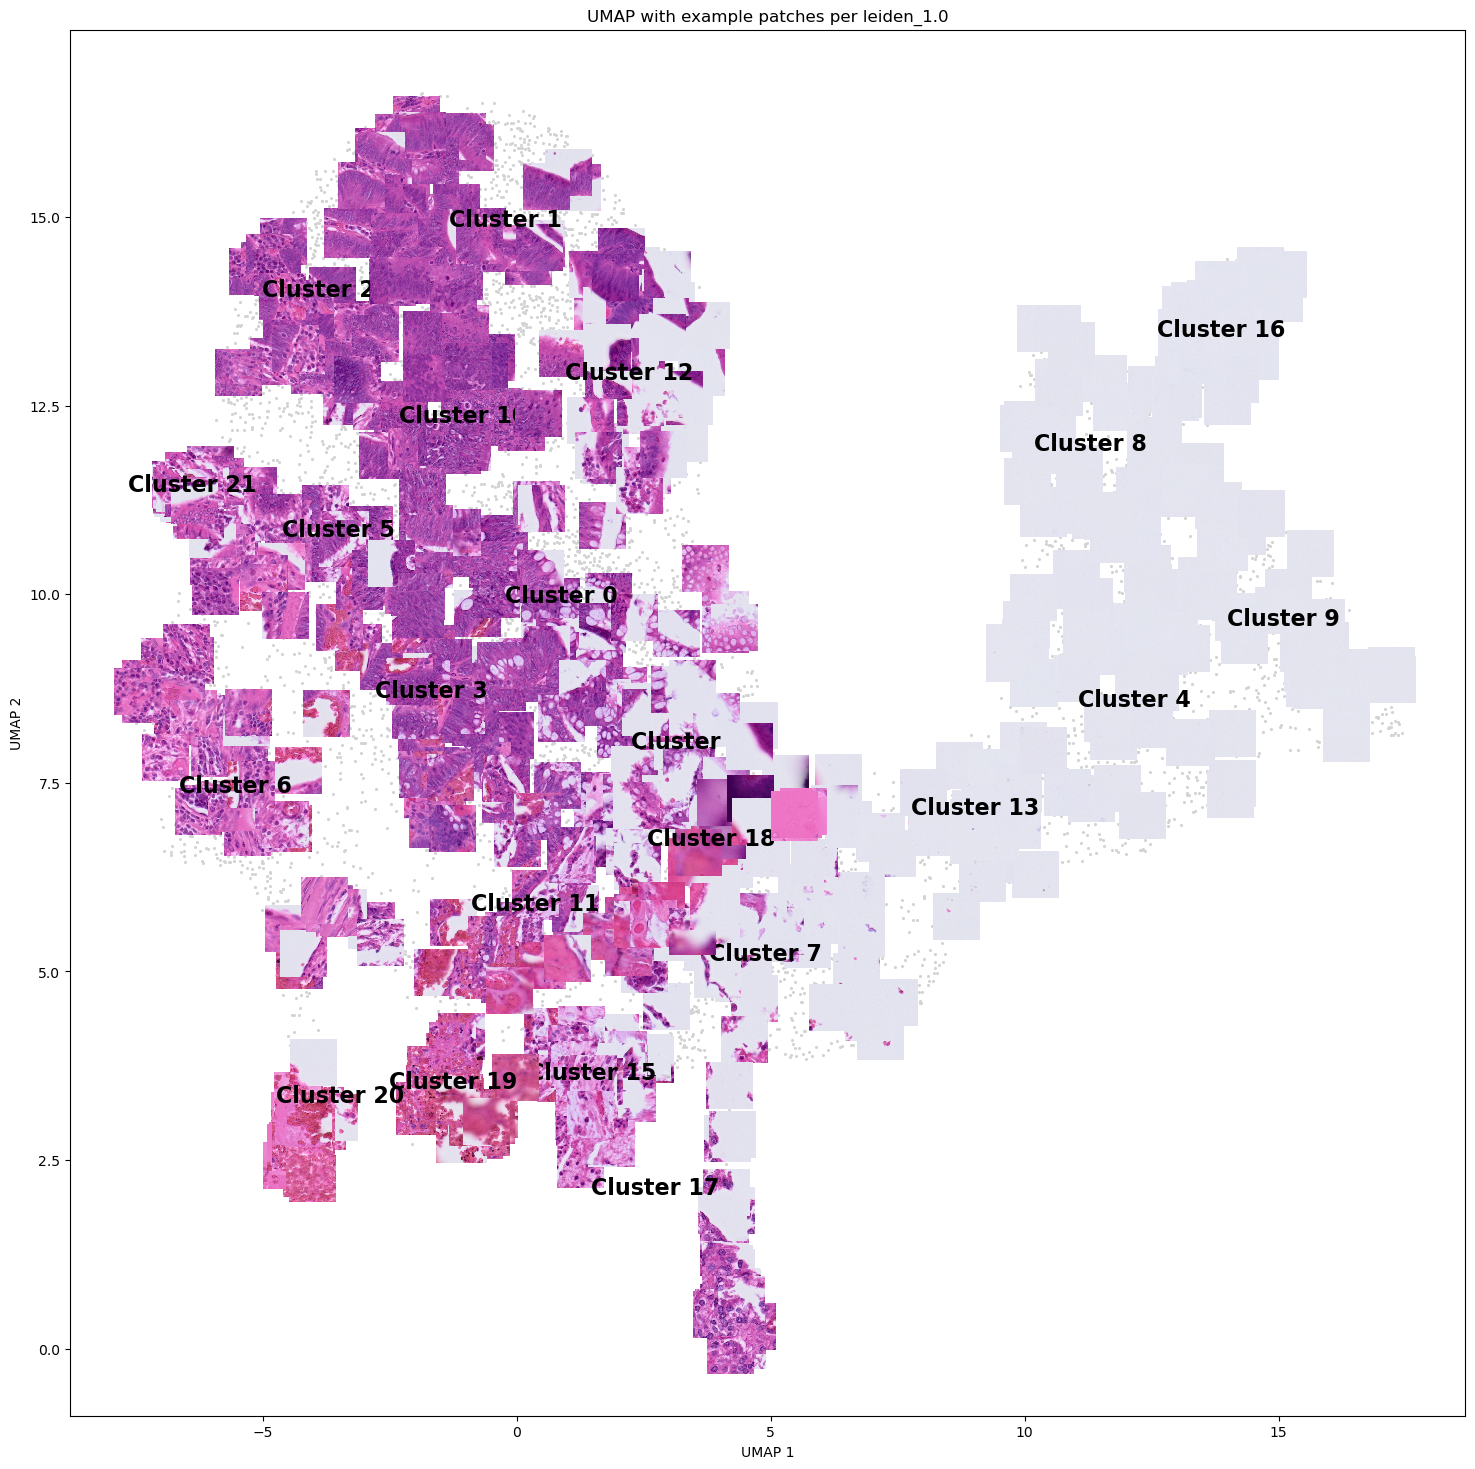

In [10]:
pl.plot_cluster_example_patches(adata, 
                                cluster_key=f"leiden_{chosen_res}", 
                                basedir=basedir)
plt.show()

In [11]:
adata.write(f"{dir_metadata}/WSI_patch_metadata.h5ad") # adds leiden info pre-filter

## 2. Filtering clusters with no tisssue 
In the following, we filter out clusters that have no tissue in it.
Note, that there can be clusters where there seems to be some patches with and without tissues.  
We then re-run PCA, the neighbor graph, UMAP and leiden and store the new filtered AnnData Object in the metadata folder as "filtered_WSI_patch_embeddings.h5ad".

Use the following cell to filter out any cluster that only has background information. 
Adapt `remove_clusters` to the clusters you want to remove before running the cell.    
This also stores the unfiltered patch embeddings in the patch folder for each sample. 

In [12]:
remove_clusters = ['4', '8', '9', '13', '16'] # Adapt based on the clusters you want to remove. See plot above.

adata_filter = adata[~adata.obs[f"leiden_{chosen_res}"].isin(remove_clusters)].copy()
adata_filter.write(Path(f"{dir_metadata}/filtered_WSI_patch_embeddings.h5ad"))

# 3. Re-running clustering and plot new clusters
Now we only plot clusters with tissue in it. 
For this, we also rerun clustering methods such as PCA and leiden on only the sub-selection of patches that are the result of the previous step. 

In [13]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random

In [14]:
# Run this cell if you did not run step 1 during this session and have already created the filtered patch embeddings. 
if not Path(dir_metadata).is_dir():
    raise NotADirectoryError(f"The directory {dir_metadata} does not exist.")

try:
    adata_filter = sc.read_h5ad(f"{dir_metadata}/filtered_WSI_patch_embeddings.h5ad")
    adata_filter.obs
except NotADirectoryError:
    print("The file filtered_WSI_patch_embeddings.h5ad does not exist in the metadata directory.")
    

Remove old leiden information, then rerun PCA, set neighbors and then run UMAP and leiden again. 
Finally, we plot the UMAP graph again.

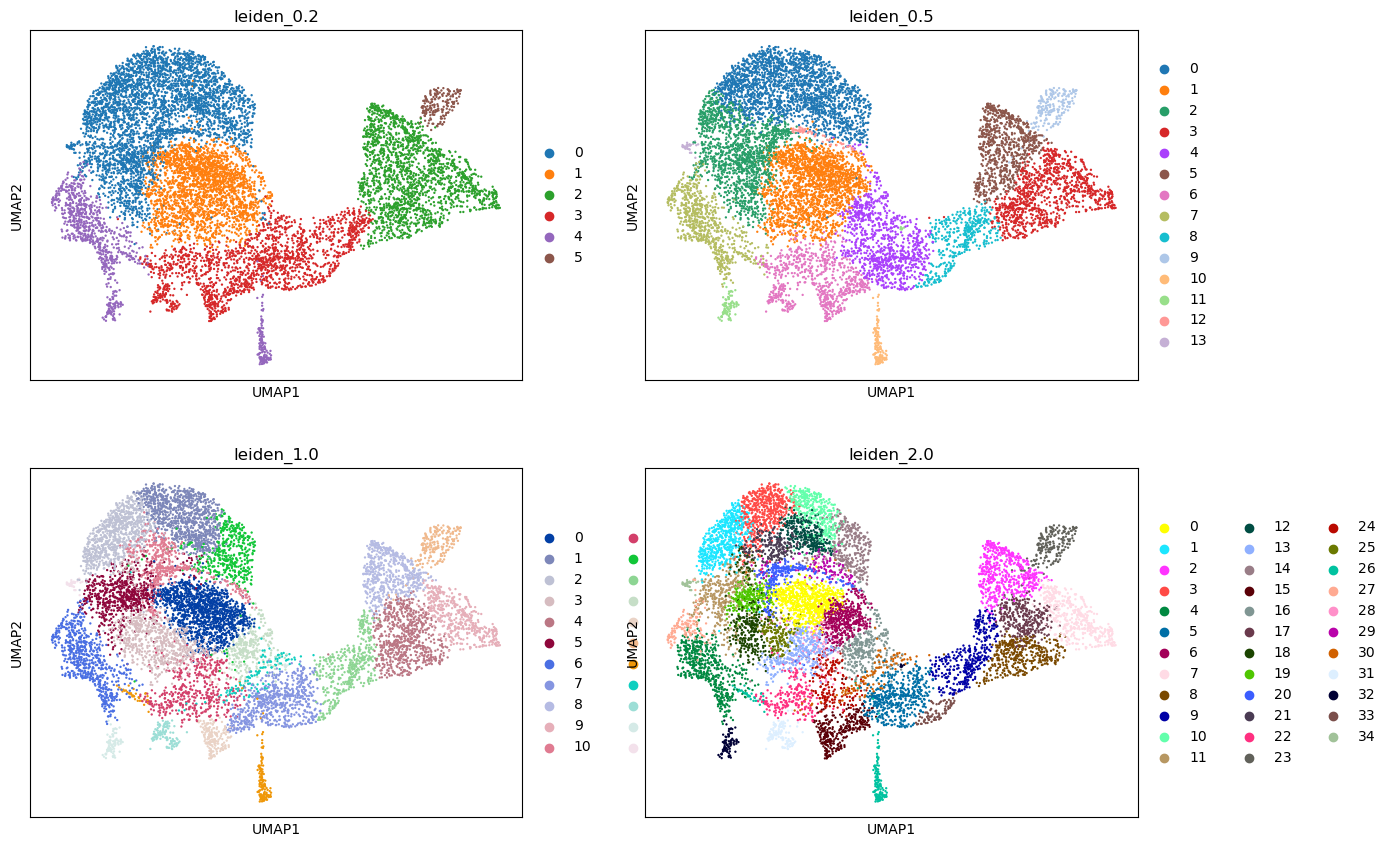

<Figure size 640x480 with 0 Axes>

In [15]:
# Delete leiden columns
for res in leiden_res:
    if f"leiden_{res}" in adata_filter.obs:
        del adata_filter.obs[f"leiden_{res}"]
    if f"leiden_{res}" in adata_filter.uns:
        del adata_filter.uns[f"leiden_{res}"]


# Re-run PCA and leiden on filtered patch embeddings
sc.pp.pca(adata_filter, n_comps=50)
sc.pp.neighbors(adata_filter, use_rep="X_pca")
sc.tl.umap(adata_filter)

run_leiden(adata_filter, leiden_res)

# plotting umap
umap_res = ["leiden_0.2", "leiden_0.5", "leiden_1.0", "leiden_2.0"]

sc.pl.umap(adata, 
           color=umap_res, 
           ncols=2)

plt.suptitle(f"Post-patch-filtering UMAP Comparison for sample {sample} with leiden clusters: {umap_res}", fontsize=16, y=1.02)
plt.show()

In [16]:
print(adata_filter.obs["Slide_ID"].unique())  # Check unique slide IDs in the filtered data

['CRC_P11mm_2_cut']
Categories (1, object): ['CRC_P11mm_2_cut']


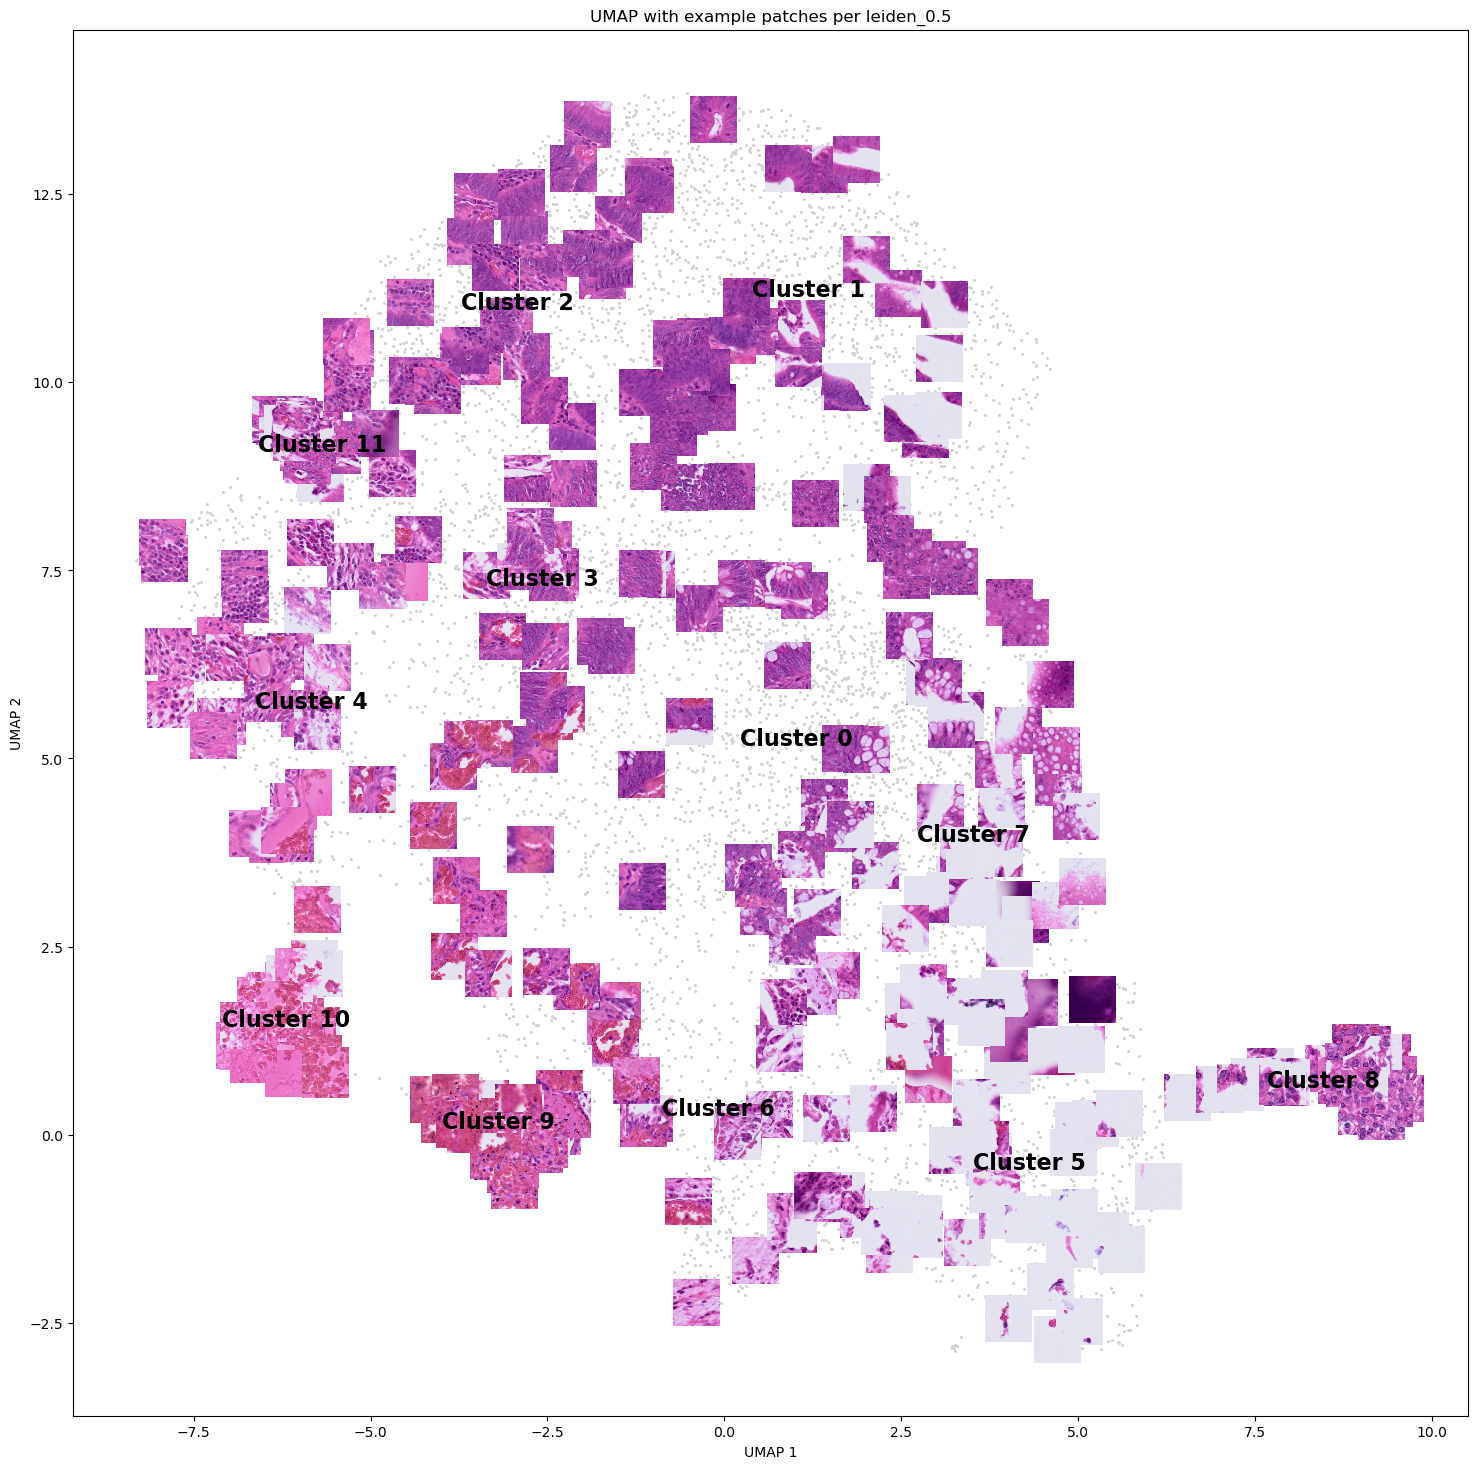

In [17]:
new_leiden_res = 0.5 # set this to desired leiden resolution
pl.plot_cluster_example_patches(adata_filter, cluster_key=f"leiden_{new_leiden_res}", basedir=basedir)
plt.show()

**IMPORTANT**: Dont forget to save the file with the cell below.

In [18]:
adata_filter.write(f"{dir_metadata}/filtered_WSI_patch_embeddings.h5ad")

After filtering out the patches, we can also filter out the tokens that were in those patches:

In [6]:
exclude_dirs = [""]
#samples = [p.name for p in Path(basedir).iterdir() if (p.is_dir())]
samples = ["CRC_P3_SMAP"]

for sample in samples: 
    # Load filtered patch embedding metadata
    adata_filtered = sc.read_h5ad(basedir / sample / "01_preprocessing/unimodel/metadata/filtered_WSI_patch_embeddings.h5ad", backed="r")

    # Create a set - group valid Patch_IDs per Slide_ID from filtered file
    valid_patches = set(
        zip(adata_filtered.obs["Slide_ID"], adata_filtered.obs["Patch_ID"])
    )

    adata_filtered.file.close()

    # Load token embeddings
    # (Use backed="r" if token file is too large for RAM)
    adata_tokens = sc.read_h5ad(basedir / sample / "01_preprocessing/unimodel/metadata/WSI_patch_token_embeddings.h5ad")

    # Boolean mask to match token file's rows to valid set
    token_patch_keys = list(
        zip(adata_tokens.obs["Slide_ID"], adata_tokens.obs["Patch_ID"])
    )
    mask = [key in valid_patches for key in token_patch_keys]

    # Filter token object to keep only matching patches
    adata_tokens_filtered = adata_tokens[mask].copy()

    # save
    adata_tokens_filtered.write_h5ad(basedir / sample / "01_preprocessing/unimodel/metadata/WSI_patch_token_embeddings_filtered.h5ad")

    print(f"Original tokens shape: {adata_tokens.shape}")
    print(f"Filtered tokens shape: {adata_tokens_filtered.shape}")

Original tokens shape: (3444736, 1536)
Filtered tokens shape: (3214336, 1536)


### Merge the created file to one super file

In [5]:
from functions.merge import merge_anndatas

# Merge all sample AnnData objects using the shared helper, 
# --> keeps UMAP embeddings stored safely per-sample
path_template_unimodel = "{basedir}/{sample}/01_preprocessing/unimodel/metadata/{filename}"

exclude_dirs = {"new", "combined"}
all_samples = [p.name for p in basedir.iterdir() if p.is_dir() and p.name not in exclude_dirs]

merged_filtered = merge_anndatas(
    all_samples, path_template_unimodel, "filtered_WSI_patch_embeddings.h5ad", basedir,
    obs_name_mode="unique", additional_per_sample_obsm_keys=("X_umap",),
)
merged_unfiltered = merge_anndatas(
    all_samples, path_template_unimodel, "WSI_patch_metadata.h5ad", basedir,
    obs_name_mode="unique", additional_per_sample_obsm_keys=("X_umap",),
)

merged_tokens_filtered = merge_anndatas(
    all_samples, path_template_unimodel, "WSI_patch_token_embeddings_filtered.h5ad", basedir,
    obs_name_mode="unique",
    merge_mode="incremental",
)


Preserved per-sample embedding(s) under obsm[...'_per_sample_raw'] (filter by obs['Slide_ID'] to recover one sample's own coordinates), uns['pca_loadings_per_sample'], and uns['pca_variance_ratio_per_sample']. Call sc.pp.pca(adata_merged, ...) / sc.tl.umap(adata_merged, ...) separately for a real joint, cross-sample-comparable embedding.
Merged 10/10 sample(s) -> ../../../../data/combined/01_preprocessing/unimodel/metadata/filtered_WSI_patch_embeddings.h5ad
Preserved per-sample embedding(s) under obsm[...'_per_sample_raw'] (filter by obs['Slide_ID'] to recover one sample's own coordinates). Call sc.pp.pca(adata_merged, ...) / sc.tl.umap(adata_merged, ...) separately for a real joint, cross-sample-comparable embedding.
Merged 10/10 sample(s) -> ../../../../data/combined/01_preprocessing/unimodel/metadata/WSI_patch_metadata.h5ad
Incremental merge: 2 new sample(s) to add (['CRC_P3_SMAP', 'CRC_P4_SMAP']), 8 already present.
Merged 2 new sample(s) into the existing 8 -> ../../../../data/com

# Plotting the clusters 

In [7]:
import scanpy as sc 
import os 
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import matplotlib.patches as patches
import pandas as pd
import numpy as np

sample = "CRC_P11mm_2_cut"
cluster_col = "leiden_0.2" # cluster resolution
patch_size = 224

dir_metadata = basedir / "combined/01_preprocessing/unimodel/metadata"

adata = sc.read_h5ad(f"{dir_metadata}/filtered_WSI_patch_embeddings.h5ad")
# only plot for chosen sample:
adata = adata[adata.obs["Slide_ID"] == sample] 

# Extract needed info
df = adata.obs[["Slide_ID", "X", "Y", cluster_col]].copy()

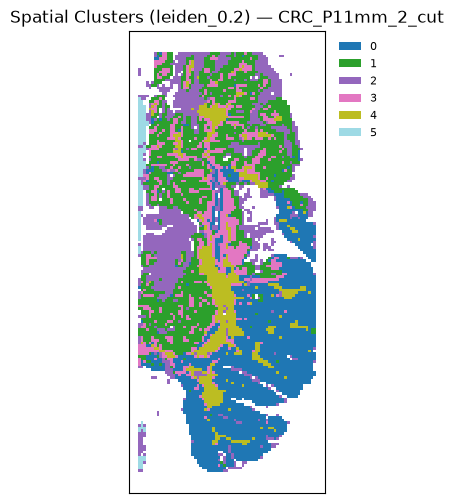

In [8]:
pl.plot_spatial_labels(
    adata,
    spatial_key="spatial",
    label_key=cluster_col,
    title=f"Spatial Clusters ({cluster_col}) — {sample}",
    mode="patch",
    patch_size=patch_size,
)
plt.show()